# Color-Coded Cryptocurrency Price Charts

This tutorial colors line segments by the sign and magnitude of daily returns. A deterministic Bitcoin-like fixture keeps the visualization reproducible; the same plotting function can be applied to validated market data.

In [1]:
from pathlib import Path

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize

RANDOM_SEED = 71
OUTPUT_DIR = Path('generated/visualization-071')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(RANDOM_SEED)
dates = pd.date_range('2025-01-01', periods=240, freq='D')
daily_returns = rng.normal(0.001, 0.025, len(dates))
prices = pd.Series(45_000 * np.exp(np.cumsum(daily_returns)), index=dates, name='BTC_USD')
market = prices.to_frame()
market['return_1d'] = market['BTC_USD'].pct_change()
print(market.describe().round(3).to_string())

         BTC_USD  return_1d
count    240.000    239.000
mean   41628.487     -0.000
std     3962.814      0.021
min    34722.710     -0.053
25%    38263.242     -0.015
50%    40984.154     -0.000
75%    45376.028      0.014
max    50349.851      0.071


## 1. Convert the Series into Colored Segments

`LineCollection` draws each interval separately and maps the return observed at the end of that interval to a diverging color scale.

In [2]:
def colored_price_line(axis, price_series, return_series):
    x_values = mdates.date2num(price_series.index.to_pydatetime())
    y_values = price_series.to_numpy()
    points = np.column_stack([x_values, y_values]).reshape(-1, 1, 2)
    segments = np.concatenate([points[:-1], points[1:]], axis=1)
    scale_limit = np.nanquantile(np.abs(return_series), 0.98)
    normalization = Normalize(vmin=-scale_limit, vmax=scale_limit)
    collection = LineCollection(
        segments,
        cmap='RdYlGn',
        norm=normalization,
        linewidth=2.2,
    )
    collection.set_array(return_series.iloc[1:].to_numpy())
    axis.add_collection(collection)
    axis.set_xlim(x_values.min(), x_values.max())
    axis.set_ylim(y_values.min() * 0.97, y_values.max() * 1.03)
    axis.xaxis_date()
    return collection

## 2. Plot Price and Return Context

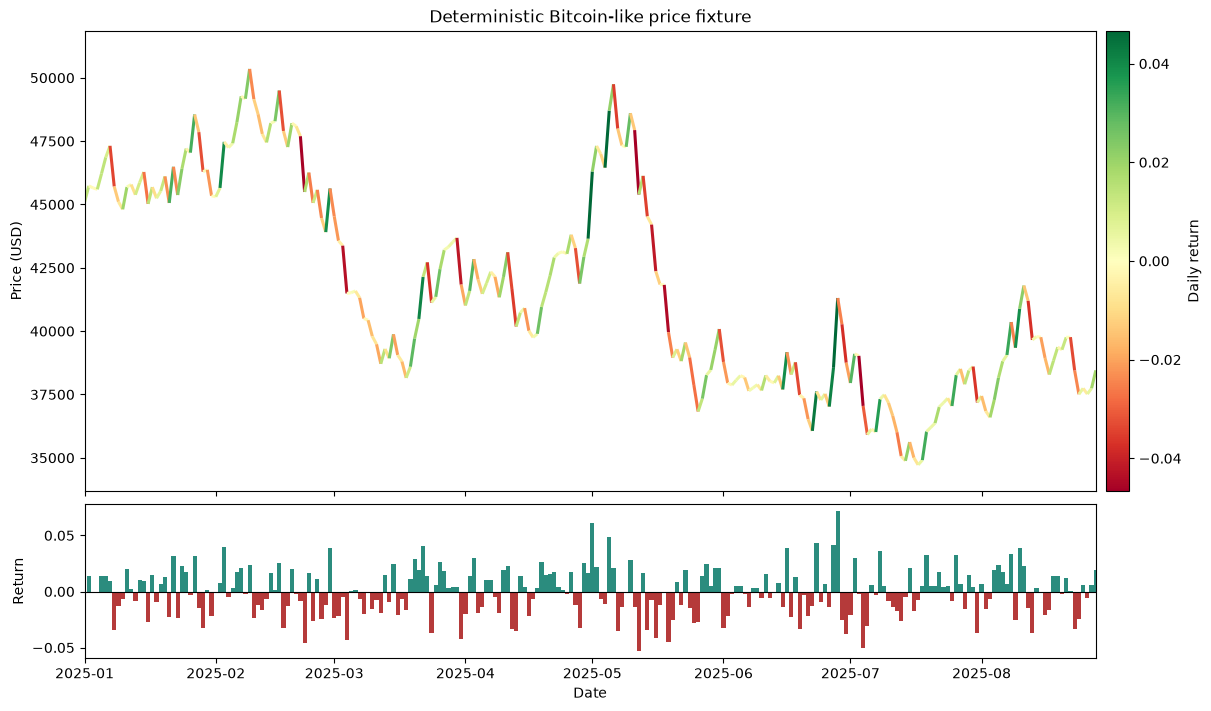

saved: generated\visualization-071\color-coded-crypto-price.png


In [3]:
figure, axes = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True,
    gridspec_kw={'height_ratios': [3, 1]}, constrained_layout=True
)
collection = colored_price_line(axes[0], market['BTC_USD'], market['return_1d'])
axes[0].set(title='Deterministic Bitcoin-like price fixture', ylabel='Price (USD)')
colorbar = figure.colorbar(collection, ax=axes[0], pad=0.01)
colorbar.set_label('Daily return')
axes[1].bar(
    market.index,
    market['return_1d'],
    color=np.where(market['return_1d'].ge(0), '#2b8c7e', '#b53a3a'),
    width=1.0,
)
axes[1].axhline(0, color='black', linewidth=0.8)
axes[1].set(ylabel='Return', xlabel='Date')
figure_path = OUTPUT_DIR / 'color-coded-crypto-price.png'
figure.savefig(figure_path, dpi=170, bbox_inches='tight')
plt.show()
print(f'saved: {figure_path}')